In [1]:
import pandas as pd
import xgboost as xgb
import torch
from sklearn.model_selection import train_test_split
import importlib.metadata

print("XGBoost:", importlib.metadata.version("xgboost"))
print("PyTorch:", importlib.metadata.version("torch"))

df = pd.read_csv('data/processed/clean_data.csv')
df.head()

XGBoost: 3.4.1
PyTorch: 2.14.0


,unit_number,time_in_cycles,op_setting_1,op_setting_2,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_20,sensor_21,sensor_2_roll_mean_5,RUL,sensor_2_roll_std_5
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,14.62,21.61,554.36,...,2388.02,8138.62,8.4195,0.03,392,39.06,23.4190,641.820000,191,0.000000
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,14.62,21.61,553.75,...,2388.07,8131.49,8.4318,0.03,392,39.00,23.4236,641.985000,190,0.233345
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,14.62,21.61,554.26,...,2388.03,8133.23,8.4178,0.03,390,38.95,23.3442,642.106667,189,0.267644
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,14.62,21.61,554.45,...,2388.08,8133.83,8.3682,0.03,392,38.88,23.3739,642.167500,188,0.250117
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,14.62,21.61,554.00,...,2388.04,8133.80,8.4294,0.03,393,38.90,23.4044,642.208000,187,0.234776


In [2]:
import numpy as np

# First, create the failing_soon label
df['failing_soon'] = (df['RUL'] <= 30).astype(int)
print("Class balance:\n", df['failing_soon'].value_counts())
print()

# Split by UNIT (engine), not by row
unique_engines = df['unit_number'].unique()
np.random.seed(42)  # reproducibility - important for a professional report
np.random.shuffle(unique_engines)

n_train = int(0.7 * len(unique_engines))
n_val = int(0.15 * len(unique_engines))

train_engines = unique_engines[:n_train]
val_engines = unique_engines[n_train:n_train+n_val]
test_engines = unique_engines[n_train+n_val:]

train_df = df[df['unit_number'].isin(train_engines)]
val_df = df[df['unit_number'].isin(val_engines)]
test_df = df[df['unit_number'].isin(test_engines)]

print(f"Train engines: {len(train_engines)}, rows: {len(train_df)}")
print(f"Val engines: {len(val_engines)}, rows: {len(val_df)}")
print(f"Test engines: {len(test_engines)}, rows: {len(test_df)}")

Class balance:
 failing_soon
0    17531
1     3100
Name: count, dtype: int64

Train engines: 70, rows: 14316
Val engines: 15, rows: 3170
Test engines: 15, rows: 3145


In [3]:
# Define feature columns - exclude identifiers and the target itself
exclude_cols = ['unit_number', 'time_in_cycles', 'RUL', 'failing_soon']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X_train, y_train = train_df[feature_cols], train_df['failing_soon']
X_val, y_val = val_df[feature_cols], val_df['failing_soon']
X_test, y_test = test_df[feature_cols], test_df['failing_soon']

print("Features used:", feature_cols)
print("Train shape:", X_train.shape)

Features used: ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21', 'sensor_2_roll_mean_5', 'sensor_2_roll_std_5']
Train shape: (14316, 21)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# --- Baseline: Logistic Regression ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_scaled, y_train)
lr_preds = log_reg.predict(X_val_scaled)
lr_probs = log_reg.predict_proba(X_val_scaled)[:, 1]

print("=== Logistic Regression Baseline (Validation Set) ===")
print(classification_report(y_val, lr_preds))
print("ROC-AUC:", roc_auc_score(y_val, lr_probs))

=== Logistic Regression Baseline (Validation Set) ===
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2705
           1       0.75      0.92      0.83       465

    accuracy                           0.94      3170
   macro avg       0.87      0.94      0.90      3170
weighted avg       0.95      0.94      0.95      3170

ROC-AUC: 0.9893339693518574


In [5]:
from xgboost import XGBClassifier

# Handle class imbalance via scale_pos_weight (XGBoost's native method)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_preds = xgb_model.predict(X_val)
xgb_probs = xgb_model.predict_proba(X_val)[:, 1]

print("=== XGBoost (Validation Set) ===")
print(classification_report(y_val, xgb_preds))
print("ROC-AUC:", roc_auc_score(y_val, xgb_probs))

=== XGBoost (Validation Set) ===
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      2705
           1       0.82      0.86      0.84       465

    accuracy                           0.95      3170
   macro avg       0.90      0.91      0.91      3170
weighted avg       0.95      0.95      0.95      3170

ROC-AUC: 0.9874306839186691


In [6]:
!pip install shap

C:\Users\anish\AppData\Local\Temp\ipykernel_32116\131937844.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_val, plot_type="bar", show=False)


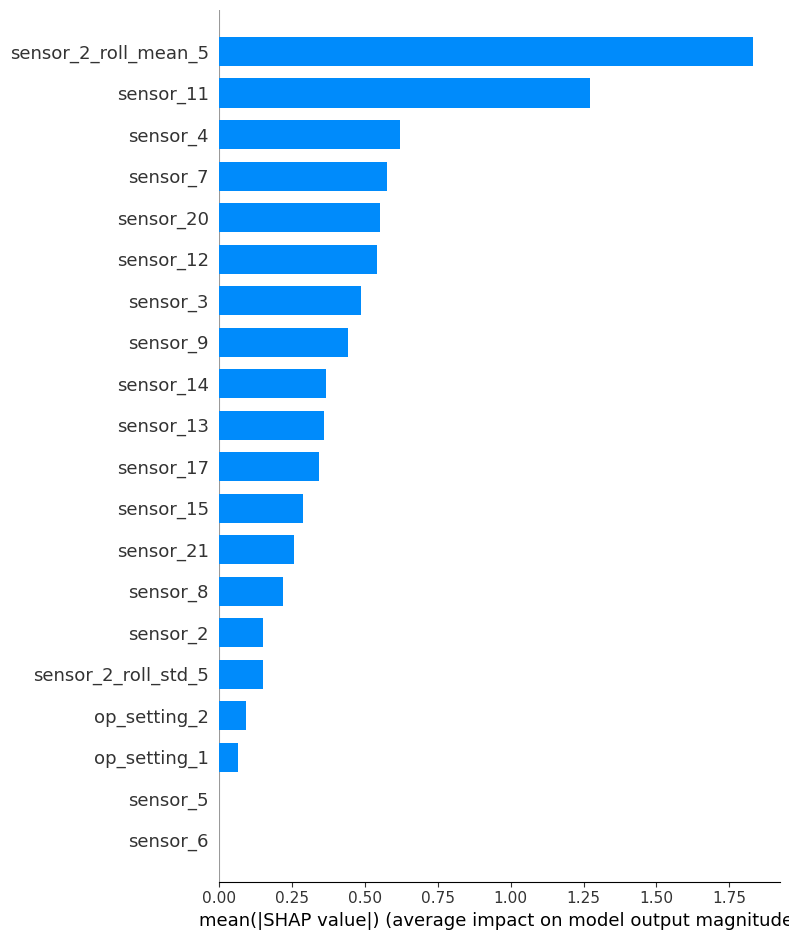

In [7]:
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val)

shap.summary_plot(shap_values, X_val, plot_type="bar", show=False)
import matplotlib.pyplot as plt
plt.tight_layout()
plt.savefig('reports/figures/shap_summary.png', dpi=150)
plt.show()

In [8]:
# Final evaluation on TEST set - touched only once, at the very end
xgb_test_preds = xgb_model.predict(X_test)
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]

print("=== XGBoost FINAL Test Set Evaluation ===")
print(classification_report(y_test, xgb_test_preds))
print("ROC-AUC:", roc_auc_score(y_test, xgb_test_probs))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_test_preds))

=== XGBoost FINAL Test Set Evaluation ===
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      2680
           1       0.81      0.90      0.85       465

    accuracy                           0.95      3145
   macro avg       0.89      0.93      0.91      3145
weighted avg       0.96      0.95      0.95      3145

ROC-AUC: 0.9889391750922806

Confusion Matrix:
[[2579  101]
 [  46  419]]


In [9]:
import os
os.makedirs('models', exist_ok=True)
xgb_model.save_model('models/xgboost_model.json')
print("Model saved to models/xgboost_model.json")

Model saved to models/xgboost_model.json


In [10]:
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# RUL target - clip extreme values (common technique in C-MAPSS research)
# Very high RUL values (engine is brand new) are less meaningful to predict precisely
RUL_CAP = 125
train_df_reg = train_df.copy()
val_df_reg = val_df.copy()
test_df_reg = test_df.copy()

train_df_reg['RUL_clipped'] = train_df_reg['RUL'].clip(upper=RUL_CAP)
val_df_reg['RUL_clipped'] = val_df_reg['RUL'].clip(upper=RUL_CAP)
test_df_reg['RUL_clipped'] = test_df_reg['RUL'].clip(upper=RUL_CAP)

# Same feature columns as before
X_train_reg = train_df_reg[feature_cols].values
X_val_reg = val_df_reg[feature_cols].values
X_test_reg = test_df_reg[feature_cols].values

y_train_reg = train_df_reg['RUL_clipped'].values
y_val_reg = val_df_reg['RUL_clipped'].values
y_test_reg = test_df_reg['RUL_clipped'].values

# Scale features - PyTorch needs this, unlike XGBoost
reg_scaler = StandardScaler()
X_train_reg_scaled = reg_scaler.fit_transform(X_train_reg)
X_val_reg_scaled = reg_scaler.transform(X_val_reg)
X_test_reg_scaled = reg_scaler.transform(X_test_reg)

# Convert to PyTorch tensors
X_train_t = torch.FloatTensor(X_train_reg_scaled)
y_train_t = torch.FloatTensor(y_train_reg).reshape(-1, 1)
X_val_t = torch.FloatTensor(X_val_reg_scaled)
y_val_t = torch.FloatTensor(y_val_reg).reshape(-1, 1)
X_test_t = torch.FloatTensor(X_test_reg_scaled)
y_test_t = torch.FloatTensor(y_test_reg).reshape(-1, 1)

print("Train tensor shape:", X_train_t.shape)
print("Sample RUL values (clipped):", y_train_reg[:10])

Train tensor shape: torch.Size([14316, 21])
Sample RUL values (clipped): [125 125 125 125 125 125 125 125 125 125]


In [11]:
class RULPredictor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.network(x)


In [12]:
input_dim = X_train_t.shape[1]
model = RULPredictor(input_dim)
print(model)

RULPredictor(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [13]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 100
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t)
        val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{n_epochs}], Train Loss: {loss.item():.2f}, Val Loss: {val_loss.item():.2f}")

Epoch [10/100], Train Loss: 9244.53, Val Loss: 9449.35
Epoch [20/100], Train Loss: 9232.15, Val Loss: 9437.13
Epoch [30/100], Train Loss: 9217.09, Val Loss: 9420.14
Epoch [40/100], Train Loss: 9189.59, Val Loss: 9388.10
Epoch [50/100], Train Loss: 9131.33, Val Loss: 9318.84
Epoch [60/100], Train Loss: 9010.42, Val Loss: 9174.63
Epoch [70/100], Train Loss: 8773.97, Val Loss: 8893.31
Epoch [80/100], Train Loss: 8348.47, Val Loss: 8388.69
Epoch [90/100], Train Loss: 7647.56, Val Loss: 7556.26
Epoch [100/100], Train Loss: 6577.76, Val Loss: 6325.01


In [14]:
# Continue training with more epochs and a learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=20)

n_epochs = 400
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t)
        val_losses.append(val_loss.item())

    scheduler.step(val_loss)

    if (epoch + 1) % 25 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch [{epoch+1}/{n_epochs}], Train Loss: {loss.item():.2f}, Val Loss: {val_loss.item():.2f}, LR: {current_lr:.6f}")

Epoch [25/400], Train Loss: 3267.37, Val Loss: 2806.08, LR: 0.001000
Epoch [50/400], Train Loss: 2512.79, Val Loss: 2299.65, LR: 0.001000
Epoch [75/400], Train Loss: 2040.39, Val Loss: 1741.21, LR: 0.001000
Epoch [100/400], Train Loss: 1615.99, Val Loss: 1313.33, LR: 0.001000
Epoch [125/400], Train Loss: 1280.06, Val Loss: 981.19, LR: 0.001000
Epoch [150/400], Train Loss: 1084.77, Val Loss: 777.54, LR: 0.001000
Epoch [175/400], Train Loss: 919.03, Val Loss: 655.83, LR: 0.001000
Epoch [200/400], Train Loss: 843.17, Val Loss: 585.38, LR: 0.001000
Epoch [225/400], Train Loss: 790.11, Val Loss: 544.64, LR: 0.001000
Epoch [250/400], Train Loss: 757.30, Val Loss: 519.60, LR: 0.001000
Epoch [275/400], Train Loss: 728.24, Val Loss: 500.56, LR: 0.001000
Epoch [300/400], Train Loss: 712.38, Val Loss: 483.61, LR: 0.001000
Epoch [325/400], Train Loss: 698.86, Val Loss: 468.63, LR: 0.001000
Epoch [350/400], Train Loss: 662.54, Val Loss: 454.07, LR: 0.001000
Epoch [375/400], Train Loss: 653.61, Val 

In [15]:
# Final test set evaluation
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    test_loss = criterion(test_outputs, y_test_t)
    test_rmse = torch.sqrt(test_loss)

    # Mean Absolute Error - more interpretable than MSE for a report
    test_mae = torch.mean(torch.abs(test_outputs - y_test_t))

print(f"=== PyTorch RUL Model - FINAL Test Set Evaluation ===")
print(f"Test MSE: {test_loss.item():.2f}")
print(f"Test RMSE: {test_rmse.item():.2f} cycles")
print(f"Test MAE: {test_mae.item():.2f} cycles")

=== PyTorch RUL Model - FINAL Test Set Evaluation ===
Test MSE: 480.34
Test RMSE: 21.92 cycles
Test MAE: 17.64 cycles


In [16]:
torch.save(model.state_dict(), 'models/pytorch_model.pth')
print("Model saved to models/pytorch_model.pth")

Model saved to models/pytorch_model.pth
